# Phishing website detection with interpretable baselines

**Research question.** How well can a Logistic Regression baseline and a Random Forest distinguish phishing from legitimate websites using the engineered indicators in the Kaggle Phishing Website Dataset, and what do false negatives and false positives mean for a security team?

This is an independent, reproducible classroom analysis. It uses the Kaggle dataset `akashkr/phishing-website-dataset` (11,055 rows; 30 predictors, plus a row index and target in the CSV). The Kaggle file mirrors the UCI Phishing Websites benchmark. It contains engineered categorical indicators, not live URLs or page content. The target is `Result`: `-1` phishing, `1` legitimate; the notebook converts phishing to the positive class. No network requests are sent to websites.

**Scope:** offline classification for learning, not an operational blocking product. All models use a stratified held-out test split; no test data is used to fit preprocessing or tune thresholds.

## Reproduce the environment

From the repository root, install dependencies and download the cited Kaggle dataset (Kaggle account/API token required):

```sh
python -m venv .venv
source .venv/bin/activate  # Windows: .venv\\Scripts\\activate
python -m pip install -r requirements-analysis.txt
python -m pip install kaggle
kaggle datasets download -d akashkr/phishing-website-dataset --unzip -p data
jupyter lab analysis/phishing_analysis.ipynb
```

Keep the downloaded CSV at `data/dataset.csv`. The raw dataset is excluded from Git; see `data/README.md`. Run notebook cells from any working directory; the loader searches common local and Kaggle paths.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

SEED = 42
sns.set_theme(style="whitegrid", palette="crest")
ROOT = Path.cwd()
if not (ROOT / "requirements-analysis.txt").exists() and (ROOT.parent / "requirements-analysis.txt").exists():
    ROOT = ROOT.parent
OUT = ROOT / "reports" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
possible = [ROOT / "data" / "dataset.csv", ROOT / "dataset.csv",
            Path("/kaggle/input/phishing-website-dataset/dataset.csv"),
            Path("/kaggle/input/phishing-website-dataset/data.csv")]
DATA_PATH = next((p for p in possible if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Download from Kaggle and place dataset.csv in data/.")
df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH.name}: {df.shape[0]:,} records × {df.shape[1]} columns")
display(df.head())

Loaded dataset.csv: 11,055 records × 32 columns


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


## Data quality and target distribution

The Kaggle CSV contains a sequential `index` column in addition to 30 predictors and `Result`. The index is metadata and is removed before modeling. Missing-value handling stays inside each model pipeline so any imputation statistics are learned from training data only. Duplicate rows are checked before splitting.

,value,meaning
records,11055,records
columns,32,CSV columns
missing_cells,0,missing cells
exact_duplicate_rows,0,exact duplicate CSV rows
repeated_profiles,5206,repeated predictor/label profiles (index removed)
conflicting_profiles,64,profiles with conflicting labels
unique_index_values,11055,unique row-index values


Target values: {-1: 4898, 1: 6157}
Target share: {-1: 0.4431, 1: 0.5569}
Predictor columns: 30  | dtypes: {dtype('int64'): 30}
Unique-value counts (predictors):


,number_of_features
unique_values_per_feature,
2,22
3,8


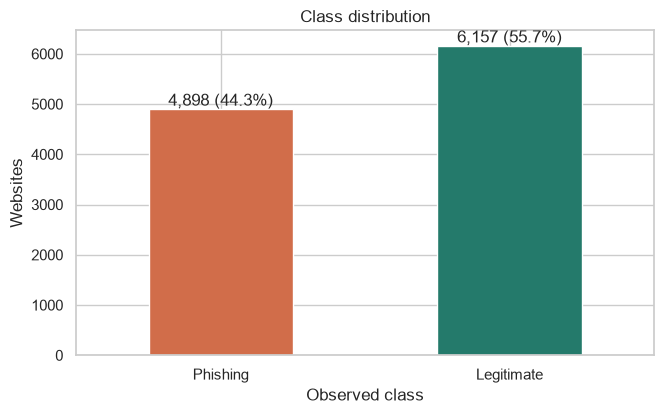

In [2]:
target_col = "Result"
assert target_col in df.columns, f"Expected target column {target_col!r}"
without_index = df.drop(columns=["index"], errors="ignore")
feature_label_duplicates = int(without_index.duplicated().sum())
conflicting_profiles = int(without_index.groupby(list(without_index.columns[:-1]))[target_col].nunique().gt(1).sum())
quality = pd.DataFrame({
    "value": [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()),
              feature_label_duplicates, conflicting_profiles,
              int(df["index"].nunique()) if "index" in df.columns else np.nan],
    "meaning": ["records", "CSV columns", "missing cells", "exact duplicate CSV rows",
                "repeated predictor/label profiles (index removed)", "profiles with conflicting labels",
                "unique row-index values"]
}, index=["records", "columns", "missing_cells", "exact_duplicate_rows", "repeated_profiles", "conflicting_profiles", "unique_index_values"])
display(quality)
print("Target values:", df[target_col].value_counts(dropna=False).sort_index().to_dict())
print("Target share:", df[target_col].value_counts(normalize=True).sort_index().round(4).to_dict())
feature_preview = df.drop(columns=[target_col, "index"], errors="ignore")
print("Predictor columns:", feature_preview.shape[1], " | dtypes:", feature_preview.dtypes.value_counts().to_dict())
print("Unique-value counts (predictors):")
display(feature_preview.nunique().value_counts().sort_index().rename_axis("unique_values_per_feature").to_frame("number_of_features"))

fig, ax = plt.subplots(figsize=(6.8, 4.3))
counts = df[target_col].map({-1: "Phishing", 1: "Legitimate"}).value_counts().reindex(["Phishing", "Legitimate"])
counts.plot.bar(ax=ax, color=["#d16d4a", "#247a6b"])
ax.set(title="Class distribution", xlabel="Observed class", ylabel="Websites")
ax.tick_params(axis="x", rotation=0)
for i, value in enumerate(counts): ax.text(i, value + 70, f"{value:,} ({value/len(df):.1%})", ha="center")
fig.tight_layout(); fig.savefig(OUT / "class_distribution.png", dpi=180); plt.show()

## Feature distributions and association

Features are integer-coded indicators (usually −1, 0, 1), not continuous measurements. The plots show representative URL, domain, and page indicators. Correlations describe this dataset's engineered features and should not be read as causal effects.

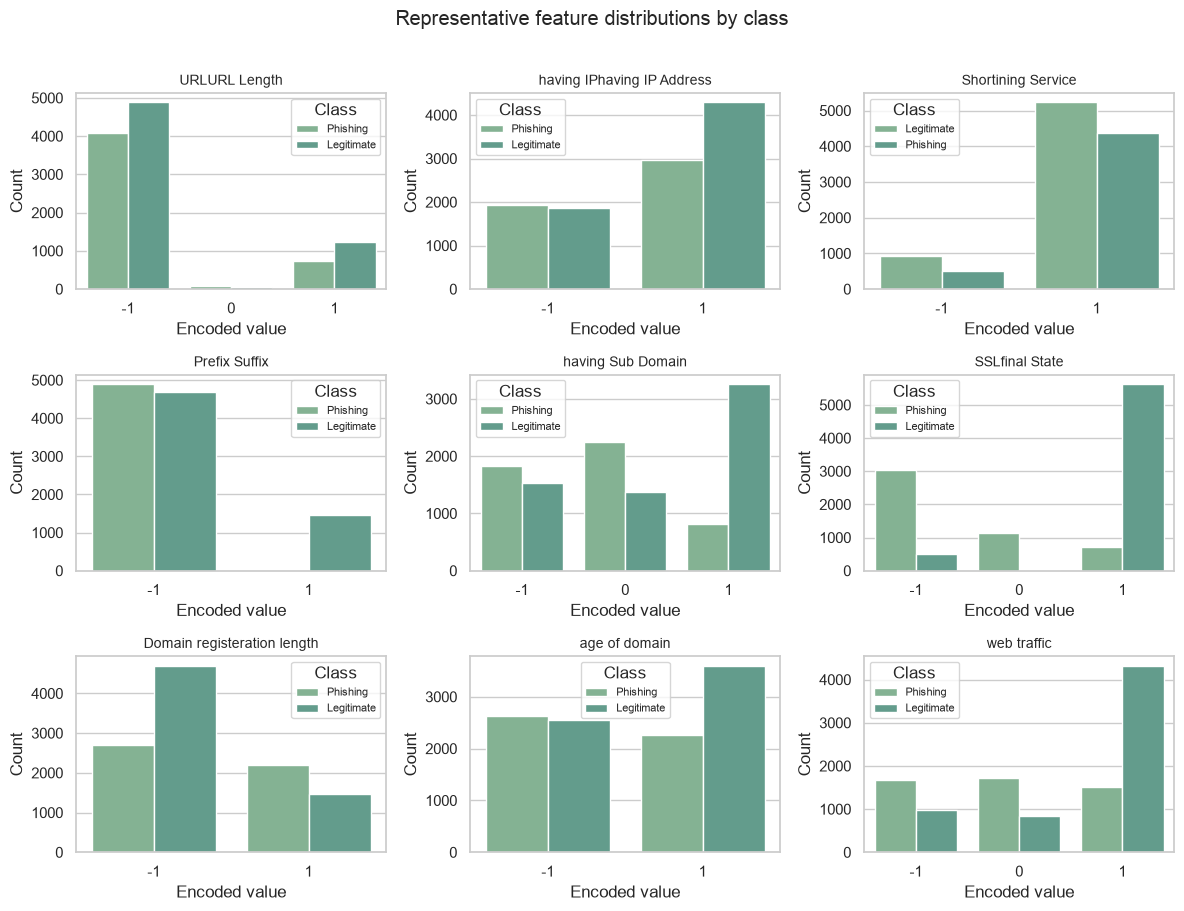

Largest absolute feature/target correlations:


,pearson_r
SSLfinal_State,0.714741
URL_of_Anchor,0.692935
Prefix_Suffix,0.348606
web_traffic,0.346103
having_Sub_Domain,0.298323
Request_URL,0.253372
Links_in_tags,0.248229
Domain_registeration_length,-0.225789
SFH,0.221419
Google_Index,0.128950


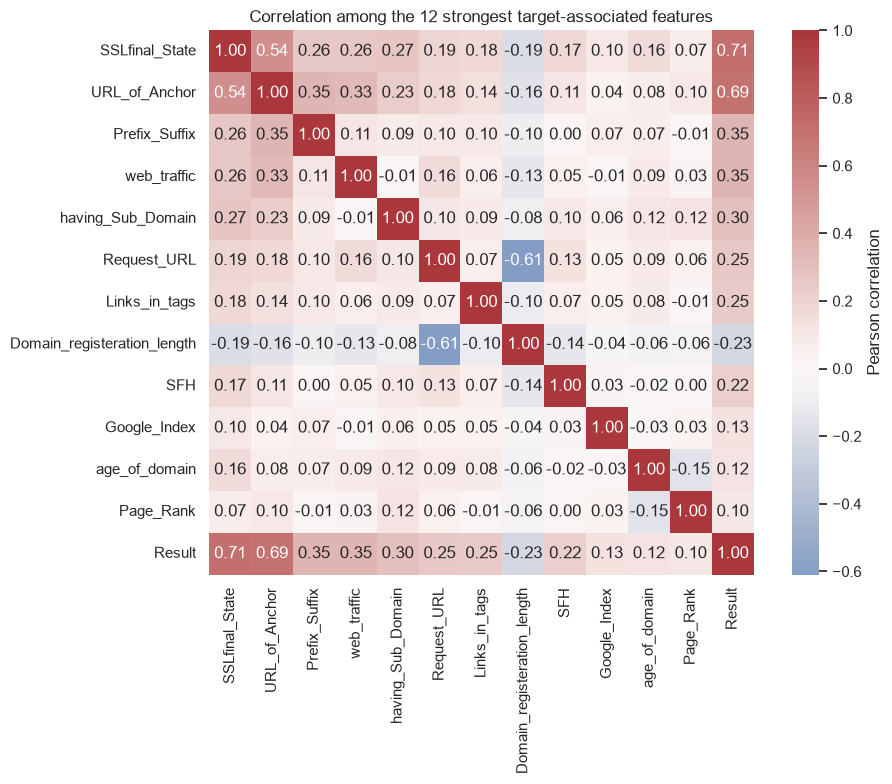

In [3]:
feature_cols = [c for c in df.columns if c not in {target_col, "index"}]
label = df[target_col].map({-1: "Phishing", 1: "Legitimate"})
selected = [c for c in ["URLURL_Length", "having_IPhaving_IP_Address", "Shortining_Service",
                        "Prefix_Suffix", "having_Sub_Domain", "SSLfinal_State",
                        "Domain_registeration_length", "age_of_domain", "web_traffic"] if c in feature_cols]
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.flat, selected):
    sns.countplot(data=pd.DataFrame({"value": df[col], "class": label}), x="value", hue="class", ax=ax)
    ax.set_title(col.replace("_", " "), fontsize=10); ax.set_xlabel("Encoded value"); ax.set_ylabel("Count")
    ax.legend(title="Class", fontsize=8)
for ax in axes.flat[len(selected):]: ax.set_visible(False)
fig.suptitle("Representative feature distributions by class", y=1.01)
fig.tight_layout(); fig.savefig(OUT / "feature_distributions.png", dpi=180, bbox_inches="tight"); plt.show()

correlations = df[feature_cols + [target_col]].corr(numeric_only=True)
target_corr = correlations[target_col].drop(target_col).sort_values(key=np.abs, ascending=False)
print("Largest absolute feature/target correlations:")
display(target_corr.head(10).rename("pearson_r").to_frame())
heat_features = target_corr.head(12).index.tolist() + [target_col]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations.loc[heat_features, heat_features], cmap="vlag", center=0, annot=True,
            fmt=".2f", square=True, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation among the 12 strongest target-associated features")
fig.tight_layout(); fig.savefig(OUT / "correlation_heatmap.png", dpi=180); plt.show()

## Preprocessing and model plan

1. Drop the sequential row index because it does not describe website risk.
2. Check exact duplicate CSV rows before removing the index. The file has none. After index removal, repeated feature/label profiles appear, and 64 predictor profiles have both target labels. Those can represent distinct websites with the same coarse engineered indicators; they are not safe to delete as duplicate records.
3. Map the dataset's `-1` phishing label to positive class `1`; legitimate becomes `0`.
4. Use a stratified, grouped 80/20 split with seed 42. Grouping by the full predictor signature prevents identical feature profiles from crossing train/test; stratification keeps the phishing share close across folds.
5. Impute numeric missing values with the training-set median inside each pipeline. The source benchmark has no missing cells, but the pipeline makes the workflow robust to them.
6. Standardize features for Logistic Regression because its regularization is scale-sensitive. Random Forest does not need scaling. All predictors are already numeric; one-hot encoding is not needed. Class weighting reduces the training objective's preference for the larger legitimate class without synthesizing examples.

Logistic Regression is an interpretable linear baseline. Random Forest captures feature interactions and nonlinear splits. The final test set is held out for one comparison; this notebook does not tune on it.

In [4]:
X = df.drop(columns=[target_col, "index"], errors="ignore").copy()
y = df[target_col].map({-1: 1, 1: 0}).astype(int)  # positive = phishing
assert set(y.unique()) == {0, 1}, "Unexpected target coding; verify source labels before continuing."
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx])), "A feature profile crossed the split."
print(f"Train: {len(X_train):,}; test: {len(X_test):,}; phishing train share: {y_train.mean():.3f}; test share: {y_test.mean():.3f}")
print(f"Exact duplicates in source: {df.duplicated().sum()}; repeated profiles retained: {feature_label_duplicates:,}; conflicting-label profiles: {conflicting_profiles}.")

numeric_features = X.columns.tolist()
linear_prep = ColumnTransformer([("numeric", Pipeline([
    ("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())
]), numeric_features)], remainder="drop")
tree_prep = ColumnTransformer([("numeric", SimpleImputer(strategy="median"), numeric_features)], remainder="drop")
models = {
    "Logistic Regression": Pipeline([("prep", linear_prep),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", tree_prep),
        ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
}
for model in models.values(): model.fit(X_train, y_train)
print("Models fitted on the training split.")

Train: 8,843; test: 2,212; phishing train share: 0.443; test share: 0.443
Exact duplicates in source: 0; repeated profiles retained: 5,206; conflicting-label profiles: 64.


Models fitted on the training split.


## Held-out evaluation

The positive class is phishing. A false negative is a phishing website labeled legitimate, which can expose users to credential or payment theft. A false positive is a legitimate website flagged for review or blocked, which creates friction and can disrupt access. Accuracy alone hides these asymmetric operational costs, so precision, recall, F1, ROC-AUC, FPR, FNR, and confusion counts are reported.

,accuracy,precision_phishing,recall_phishing,f1_phishing,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp
model,,,,,,,,,,,
Logistic Regression,0.920886,0.920585,0.898980,0.909654,0.978533,0.061688,0.101020,"1,156",76,99,881
Random Forest,0.952080,0.966880,0.923469,0.944676,0.992058,0.025162,0.076531,"1,201",31,75,905


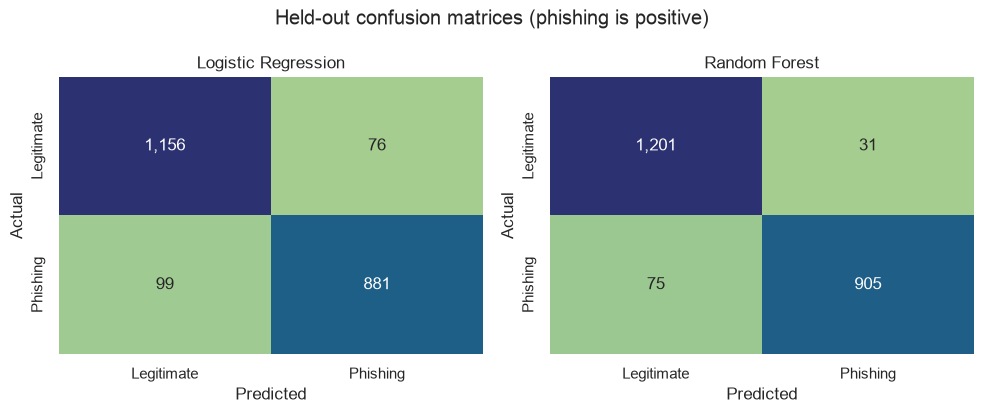

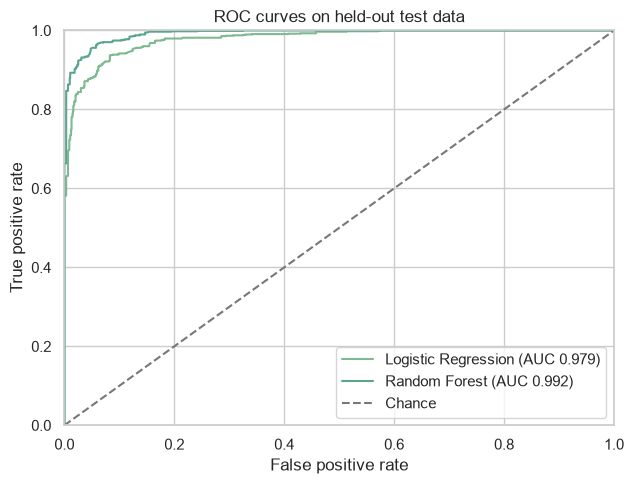

In [5]:
results = []
predictions = {}
for name, model in models.items():
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    results.append({"model": name, "accuracy": accuracy_score(y_test, pred),
        "precision_phishing": precision_score(y_test, pred, zero_division=0),
        "recall_phishing": recall_score(y_test, pred, zero_division=0),
        "f1_phishing": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, score),
        "false_positive_rate": fp / (fp + tn), "false_negative_rate": fn / (fn + tp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})
    predictions[name] = (pred, score)
metrics = pd.DataFrame(results).set_index("model")
display(metrics.style.format("{:.3f}").format({"tn":"{:,.0f}","fp":"{:,.0f}","fn":"{:,.0f}","tp":"{:,.0f}"}))
metrics.to_csv(ROOT / "reports" / "model_metrics.csv")
with open(ROOT / "reports" / "model_metrics.json", "w") as f: json.dump(metrics.reset_index().to_dict(orient="records"), f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, (pred, score)) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="crest", cbar=False, ax=ax,
                xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"])
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
fig.suptitle("Held-out confusion matrices (phishing is positive)")
fig.tight_layout(); fig.savefig(OUT / "confusion_matrices.png", dpi=180, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for name, (pred, score) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, score):.3f})")
ax.plot([0,1],[0,1], linestyle="--", color="#777", label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves on held-out test data", xlim=(0,1), ylim=(0,1))
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(OUT / "roc_curves.png", dpi=180); plt.show()

## Feature importance and security interpretation

Permutation importance measures the decrease in held-out ROC-AUC when a feature is shuffled. Correlated indicators can substitute for one another, so importance is predictive association—not causal proof or an explanation of a particular site's behavior. The data has no live URL, time, source organization, or attack campaign fields, so these results cannot identify which real attacks are hardest to detect.

,feature,mean_auc_drop,std_auc_drop
7,SSLfinal_State,0.0636,0.0032
13,URL_of_Anchor,0.0563,0.0036
25,web_traffic,0.0144,0.0019
14,Links_in_tags,0.0097,0.0008
5,Prefix_Suffix,0.0094,0.0005
6,having_Sub_Domain,0.0052,0.0007
15,SFH,0.0043,0.0008
23,age_of_domain,0.0026,0.0003
24,DNSRecord,0.0022,0.0004
28,Links_pointing_to_page,0.0019,0.0005


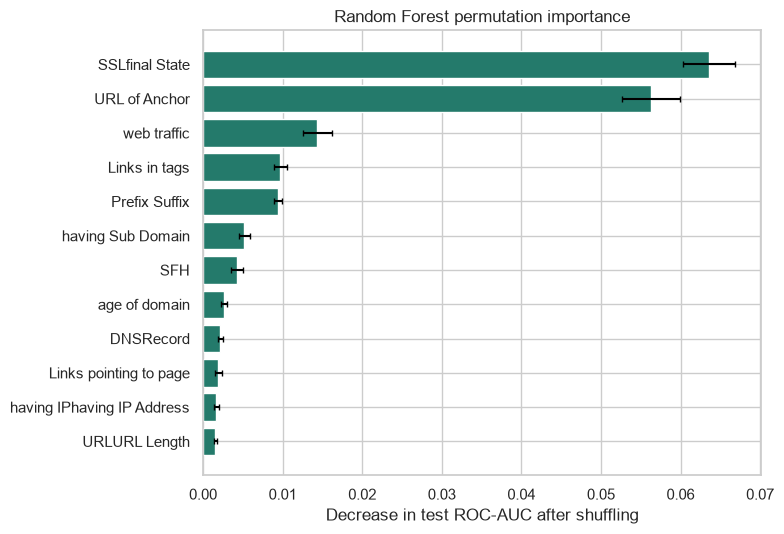

Security interpretation checklist:
• A missed phishing site (FN) is the main user-harm pathway; review recall/FNR and choose operating thresholds based on response capacity.
• A false alarm (FP) costs analyst time and may block access to legitimate services; precision/FPR quantify this burden.
• A high score on a random split is not evidence of future or cross-source performance. There is no time/source split in this benchmark.
• Use the model to prioritize investigation, not to auto-block or establish that a live URL is safe.


In [6]:
rf = models["Random Forest"]
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=10,
                              random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({"feature": X.columns, "mean_auc_drop": perm.importances_mean,
                           "std_auc_drop": perm.importances_std}).sort_values("mean_auc_drop", ascending=False)
display(importance.head(12).style.format({"mean_auc_drop":"{:.4f}","std_auc_drop":"{:.4f}"}))
importance.to_csv(ROOT / "reports" / "permutation_importance.csv", index=False)
top = importance.head(12).sort_values("mean_auc_drop")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.feature.str.replace("_", " "), top.mean_auc_drop, xerr=top.std_auc_drop, color="#247a6b", capsize=2)
ax.set(xlabel="Decrease in test ROC-AUC after shuffling", title="Random Forest permutation importance")
fig.tight_layout(); fig.savefig(OUT / "permutation_importance.png", dpi=180, bbox_inches="tight"); plt.show()

print("Security interpretation checklist:")
print("• A missed phishing site (FN) is the main user-harm pathway; review recall/FNR and choose operating thresholds based on response capacity.")
print("• A false alarm (FP) costs analyst time and may block access to legitimate services; precision/FPR quantify this burden.")
print("• A high score on a random split is not evidence of future or cross-source performance. There is no time/source split in this benchmark.")
print("• Use the model to prioritize investigation, not to auto-block or establish that a live URL is safe.")

## Limitations and conclusion

The benchmark is a static, engineered-feature dataset collected from historical sources. It omits raw pages, deployment context, temporal drift, provenance groups, and modern attacker adaptation. A random split can place similar observations on both sides, so results may overstate generalization to new campaigns. Several indicators encode heuristic judgments and may be stale. No threshold was calibrated to an operational review budget. Class weighting is a baseline response to moderate imbalance; it does not make the sample representative.

The experiment provides a reproducible comparison of one linear and one tree ensemble model. Interpret it as a controlled benchmark, not a guarantee about real-world phishing defense. A stronger deployment study would use time-based and source-separated testing, current threat feeds, calibration, subgroup/error review, drift monitoring, and analyst-in-the-loop decisions. Complete the discussion using the measured metrics above after running the notebook.

## References

- Akash Kumar. *Phishing website dataset* (Kaggle), dataset mirror: <https://www.kaggle.com/datasets/akashkr/phishing-website-dataset>.
- Rami Mohammad, Fadi Thabtah, and Lee McCluskey. “An assessment of features related to phishing websites using an automated technique.” *International Conference for Internet Technology and Secured Transactions*, 2012. Dataset record: <https://archive.ics.uci.edu/dataset/327/phishing+websites> (DOI: 10.24432/C51W2X; CC BY 4.0).
- Scikit-learn documentation: <https://scikit-learn.org/stable/>; pandas: <https://pandas.pydata.org/>; seaborn: <https://seaborn.pydata.org/>.

No external notebook or code solution was copied. Libraries are cited as tools; the preprocessing, model comparison, evaluation, visualizations, and security interpretation in this notebook are original for this project.